# Homework6 (Dueling DQN + 优先经验回放 for CartPole-v1)

在本次实验中，你将在经典 DQN 的基础上，同时引入两个进阶改进——**Dueling DQN（对偶深度 Q 网络）**与 **Prioritized Experience Replay（优先经验回放，简称 PER）**，并用它们来解决 OpenAI Gym 中的 `CartPole-v1` 环境。

## 🎯 作业目标

你的任务是补全代码中所有标记为 `【请在这里补全代码 X】` 的部分。

你需要补全的核心模块包括：

1. **`DuelingNetwork` (代码 1, 2):**
   * `__init__`: 定义共享特征层、价值流（Value Stream）和优势流（Advantage Stream）。
   * `forward`: 实现 Dueling 架构的前向传播，即 $Q(s,a) = V(s) + \big(A(s,a) - \bar{A}(s)\big)$。

2. **`PrioritizedReplayBuffer` (代码 3, 4, 5):**
   * `push`: 将经验元组存入缓冲区，并赋予初始优先级。
   * `sample`: 按优先级进行比例采样，并计算重要性采样权重。
   * `update_priorities`: 用 TD 误差更新经验的优先级。

3. **`DuelingDQNAgent` (代码 6, 7):**
   * `select_action`: 实现 ε-贪婪（Epsilon-Greedy）策略。
   * `train`: 实现带重要性采样权重的 DQN 训练逻辑，并更新采样经验的优先级。

4. **`train_dqn` (代码 8):**
   * 补全主训练循环，实现智能体与环境的交互。

## 📝 提交要求

请在补全所有代码后，从头到尾运行整个 Notebook，确保所有单元格都能正常运行，并能看到最终的训练日志和生成的 `cartpole_agent.gif` 动图。


In [1]:
# Dueling DQN + 优先经验回放 (Prioritized Experience Replay) 实现 CartPole-v1 游戏
#
# 本项目在经典 DQN 的基础上，加入了两个重要改进：
#   - Dueling DQN：把 Q 值拆分为「状态价值 V(s)」和「动作优势 A(s,a)」两部分
#   - 优先经验回放 (PER)：根据 TD 误差的大小，优先采样那些"更值得学习"的经验
import warnings                                                                           # 导入 warnings 警告管理模块
warnings.filterwarnings("ignore", category=UserWarning, message="pkg_resources is deprecated")  # 忽略 pkg_resources 弃用警告，让输出更干净
import gymnasium as gym                                                                    # 导入 Gymnasium 强化学习环境库（提供 CartPole-v1）
import numpy as np                                                                         # 导入 NumPy 数值计算库，别名 np
import torch                                                                               # 导入 PyTorch 深度学习框架
import torch.nn as nn                                                                      # 导入 PyTorch 神经网络模块，别名 nn
import torch.optim as optim                                                                # 导入 PyTorch 优化器模块，别名 optim
from collections import deque                                                              # 导入双端队列 deque，用于实现经验回放缓冲区
import random                                                                              # 导入 random 随机数模块，用于采样和探索
import matplotlib.pyplot as plt                                                           # 导入 matplotlib 绘图库，用于可视化训练曲线
from datetime import datetime                                                              # 导入 datetime 时间模块，用于 TensorBoard 日志命名
import os, time                                                                           # 导入 os 操作系统接口和 time 时间模块
from PIL import Image                                                                      # 导入 Pillow 图像处理库，用于处理图像帧
import imageio                                                                             # 导入 imageio 库，用于把图像帧合成为 GIF 动图

# 配置参数 (保留)
config = {                                                                                 # 用一个字典集中管理所有超参数
    'gamma': 0.99,                                                                         # 折扣因子：未来奖励的重要程度（越接近 1 越看重未来）
    'epsilon_start': 1.0,                                                                  # 初始探索率：一开始 100% 随机探索
    'epsilon_min': 0.001,                                                                  # 最小探索率：最低保留 0.1% 的探索
    'epsilon_decay': 0.98,                                                                 # 探索率衰减系数：每训练一个回合乘以 0.98
    'learning_rate': 0.001,                                                                # 学习率：优化器更新步长
    'batch_size': 64,                                                                      # 批次大小：每次从缓冲区采样的样本数量
    'buffer_size': 20000,                                                                  # 经验回放缓冲区容量：最多存储 2 万条经验
    'target_update_freq': 10,                                                              # 目标网络更新频率：每训练 10 步同步一次
    # ---- 以下为优先经验回放 (PER) 新增的超参数 ----
    'alpha': 0.6,                                                                          # 优先级影响系数：0=均匀采样，1=完全按优先级采样
    'beta': 0.4,                                                                           # 重要性采样系数初始值：0=不校正，1=完全校正偏差
    'beta_increment': 1e-4,                                                                # beta 每次采样的增量：训练中逐步向 1.0 靠拢
    'per_epsilon': 1e-5,                                                                   # 防止优先级为 0 的小常数，保证每条经验都有被采样机会
}                                                                                          # config 字典定义结束


## 注意

如果你没有 Pillow 和 imageio 库，可以在命令行 cmd 中用如下指令安装

`pip install imageio Pillow -i https://pypi.tuna.tsinghua.edu.cn`

如果你没有安装 CartPole-v1，可以使用如下指令安装

`pip install "gymnasium[classic-control]" -i https://pypi.tuna.tsinghua.edu.cn`


## 背景知识：Dueling DQN 与优先经验回放 (PER)

本次实验在经典 DQN 的基础上，引入两个改进，它们各自解决 DQN 的一个痛点。

### 1. Dueling DQN —— 把 Q 值拆成「价值」和「优势」

普通 DQN 直接让网络输出 $Q(s, a)$。但在很多状态下（例如 CartPole 中杆子已经接近平衡时），**选择哪个动作差别不大**，此时我们真正需要精确估计的是「这个状态本身有多好」，即状态价值 $V(s)$。

Dueling DQN 将 Q 值分解为两部分：

$$Q(s, a) = V(s) + \Big(A(s, a) - \frac{1}{|\mathcal{A}|}\sum_{a'} A(s, a')\Big)$$

* **价值流 (Value Stream)**：输出一个标量 $V(s)$，衡量状态本身的好坏。
* **优势流 (Advantage Stream)**：输出每个动作的优势 $A(s, a)$，衡量该动作相对于平均动作好多少。
* 减去优势的**均值**是为了让 $V$ 和 $A$ 可以被唯一确定（否则存在无穷多种分解方式）。

### 2. 优先经验回放 (PER) —— 优先学习「更值得学」的经验

普通经验回放**均匀随机**采样，但不同经验的学习价值差异很大：**TD 误差 (Temporal-Difference Error)** 越大的经验，说明网络对它的预测越不准，越值得被反复学习。

PER 的核心做法：

* 每条经验维护一个优先级 $p_i = |\delta_i| + \epsilon$，其中 $\delta_i$ 是 TD 误差。
* 按 $P(i) = \dfrac{p_i^{\alpha}}{\sum_j p_j^{\alpha}}$ 的概率采样（$\alpha$ 控制优先级的影响强度）。
* 由于「按优先级采样」改变了数据分布、引入了偏差，因此用**重要性采样权重** $w_i = (N \cdot P(i))^{-\beta}$ 来校正，$\beta$ 从初始值逐步增大到 1。

> 简单来说：**Dueling 改进了「网络怎么表示 Q 值」，PER 改进了「该优先回放哪些经验」。**


In [2]:
class DuelingNetwork(nn.Module):                                                         # 定义 Dueling DQN 神经网络类，继承 PyTorch 的 nn.Module
    # Dueling DQN 神经网络
    # 输入: 状态向量 (4维: 位置, 速度, 角度, 角速度)
    # 输出: 每个动作的 Q 值 (2维: 左移, 右移)
    # 核心思想: 把 Q(s,a) 拆成 V(s) + A(s,a)，V(s) 衡量状态本身价值，A(s,a) 衡量动作优势
    def __init__(self, state_size, action_size, hidden_size=256):                        # 构造函数：接收状态维度、动作维度、隐藏层大小（默认256）
        super(DuelingNetwork, self).__init__()                                           # 调用父类 nn.Module 的构造函数完成初始化
        # ==================== 【请在这里补全代码 1】 ====================
        # 目标: 定义 Dueling 网络结构
        #   1. 共享特征层 (shared feature layers): 价值流和优势流共用的全连接层
        #      - fc1: state_size -> hidden_size
        #      - fc2: hidden_size -> hidden_size
        #   2. 价值流 (value stream): 输出 1 个标量 V(s)
        #      - value_stream: hidden_size -> 1
        #   3. 优势流 (advantage stream): 输出 action_size 个标量 A(s,a)
        #      - advantage_stream: hidden_size -> action_size

        # 1. 定义共享特征层 fc1 和 fc2
        # 提示: 使用 nn.Linear(in_features, out_features)
        self.fc1=nn.Linear(state_size,hidden_size)                                                                                 # 第1层共享全连接：输入 state_size 维 → 输出 hidden_size 维
        self.fc2=nn.Linear(hidden_size,hidden_size)                                                                                 # 第2层共享全连接：输入 hidden_size 维 → 输出 hidden_size 维

        # 2. 定义价值流 value_stream（输出状态价值 V(s)）
        # 提示: 价值流只输出 1 个值，所以 out_features = 1
        self.value_stream=nn.Linear(hidden_size,1)                                                                       # 价值流：输入 hidden_size 维 → 输出 1 维（状态价值 V(s)）

        # 3. 定义优势流 advantage_stream（输出动作优势 A(s,a)）
        # 提示: 优势流输出 action_size 个值，所以 out_features = action_size
        self.advantage_stream=nn.Linear(hidden_size,action_size)                                                                                 # 优势流：输入 hidden_size 维 → 输出 action_size 维（动作优势 A(s,a)）
        # =========================================================

    def forward(self, x):                                                                # 前向传播函数：定义数据在网络中的流向
        # 前向传播
        # ==================== 【请在这里补全代码 2】 ====================
        # 目标: 完成 Dueling 架构的前向传播
        #   1. 输入 x 依次通过共享特征层 fc1、fc2，并应用 ReLU 激活
        #   2. 分别计算价值 V(s) 和优势 A(s,a)
        #   3. 组合: Q(s,a) = V(s) + (A(s,a) - A(s,a) 的均值)
        #      提示: 减去均值是为了让 V 和 A 可以被唯一确定

        # 1. 通过共享特征层并应用 ReLU 激活
        # 提示: 使用 torch.relu()
        x=torch.relu(self.fc1(x))                                                                                # 通过第1层共享全连接，并用 ReLU 激活函数引入非线性
        x=torch.relu(self.fc2(x))                                                                                 # 通过第2层共享全连接，并再次用 ReLU 激活

        # 2. 分别计算价值 V(s) 和优势 A(s,a)
        V=self.value_stream(x)                                                                                 # 价值流：得到状态价值 V(s)，形状 (batch, 1)
        A=self.advantage_stream(x)                                                       # 优势流：得到动作优势 A(s,a)，形状 (batch, action_size)
        # 3. 组合得到 Q 值
        # 提示: 对 advantage 沿动作维度求均值 (keepdim=True 保持维度)，再用 value 加上"去均值后的优势"
        q = V + (A - A.mean(dim=1, keepdim=True))                                       # 组合：Q(s,a)=V(s)+(A(s,a)-mean(A))，沿动作维度减去优势均值，使 V、A 可唯一辨识
        # =========================================================
        return q                                                                         # 返回每个动作对应的 Q 值


class PrioritizedReplayBuffer:                                                           # 定义优先经验回放缓冲区类
    # 优先经验回放缓冲区 (Prioritized Experience Replay)
    # 与普通经验回放不同：每条经验都带一个"优先级"，TD 误差越大的经验越容易被采样到
    def __init__(self, capacity, alpha=0.6, beta=0.4, beta_increment=1e-4, epsilon=1e-5):  # 构造函数：接收容量和 PER 相关超参数
        self.capacity = capacity                                                         # 保存缓冲区容量
        self.alpha = alpha                                                               # 优先级影响系数：越大则采样越偏向高优先级经验
        self.beta = beta                                                                 # 重要性采样系数（初始值）：用于校正优先级采样带来的偏差
        self.beta_increment = beta_increment                                             # beta 的增量：每次采样后 beta 逐步增大
        self.epsilon = epsilon                                                           # 防止优先级为 0 的小常数
        self.buffer = deque(maxlen=capacity)                                             # 用固定长度双端队列存储经验，超出容量自动丢弃最旧数据
        self.priorities = deque(maxlen=capacity)                                         # 用同样长度的双端队列存储优先级，与 buffer 一一对应

    def push(self, state, action, reward, next_state, done):                             # 定义"存入一条经验"的方法
        # 添加一条经验到缓冲区，并赋予初始优先级
        # ==================== 【请在这里补全代码 3】 ====================
        # 目标: 把经验元组存入缓冲区，并赋予"当前最高优先级"
        #   为什么要给最高优先级？—— 新经验还没有被学习过，应该优先被采样一次

        # 1. 计算当前缓冲区中的最大优先级（若缓冲区为空则设为 1.0）
        # 提示: 用 max(self.priorities) 取最大值，注意空缓冲区要特判
        max_priority = max(self.priorities) if self.priorities else 1.0                  # 取当前最大优先级作为新经验的初始优先级（空缓冲区默认为 1.0）

        # 2. 把经验元组追加到 buffer
        # 提示: 使用 self.buffer.append(...)
        self.buffer.append((state, action, reward, next_state, done))                   # 把 (s,a,r,s',done) 打包成元组追加到经验队列尾部

        # 3. 把初始优先级追加到 priorities（与上面的经验一一对应）
        self.priorities.append(max_priority)                                             # 把该经验的初始优先级追加到优先级队列尾部

    def sample(self, batch_size):                                                        # 定义"按优先级采样一批经验"的方法
        # 按优先级比例采样一批经验，并返回重要性采样权重
        # ==================== 【请在这里补全代码 4】 ====================
        # 目标: 按优先级概率采样 batch_size 条经验，并计算重要性采样 (Importance Sampling) 权重
        # 步骤:
        #   1. 计算采样概率 p_i = priority_i^alpha / sum(priority^alpha)
        #   2. 按概率 p 采样出 batch_size 个索引 indices
        #   3. 计算重要性采样权重 w_i = (N * p_i)^(-beta)，并归一化到最大值为 1
        #   4. 根据 indices 取出对应的经验并解压成 5 个数组
        #   5. 更新 beta (向 1.0 靠拢)

        # 1. 计算采样概率
        # 提示: 先把 self.priorities 转成 NumPy 数组，再求 priorities ** self.alpha，最后归一化
        priorities = np.array(self.priorities, dtype=np.float64)                         # 把优先级队列转成 NumPy 浮点数组，便于向量化计算
        probs = priorities ** self.alpha                                                 # 对优先级求 alpha 次幂，放大高优先级经验的相对概率
        probs = probs / probs.sum()                                                      # 归一化：让所有概率之和为 1

        # 2. 按概率采样 batch_size 个索引
        # 提示: 使用 np.random.choice(len(self.buffer), size=batch_size, p=probs)
        indices = np.random.choice(len(self.buffer), size=batch_size, p=probs)           # 按概率分布随机抽取 batch_size 个经验的索引（允许重复）

        # 3. 计算重要性采样权重
        # 提示: weights = (len(self.buffer) * probs[indices]) ** (-self.beta)
        weights = (len(self.buffer) * probs[indices]) ** (-self.beta)                    # 用公式 (N*p_i)^(-beta) 计算每条经验的校正权重
        weights = weights / weights.max()                                                # 把权重归一化到最大值为 1（只缩放、不影响梯度方向）

        # 4. 根据索引取出对应经验并解压
        batch = [self.buffer[idx] for idx in indices]                                    # 按采样索引取出对应的经验元组，组成一个列表
        states, actions, rewards, next_states, dones = zip(*batch)                       # 用 zip(*batch) 把"经验列表"按列解压成 5 个独立元组

        # 5. 更新 beta（重要性采样系数逐步向 1.0 靠拢）
        # 提示: self.beta = min(1.0, self.beta + self.beta_increment)
        self.beta = min(1.0, self.beta + self.beta_increment)                            # 每采样一次，beta 向 1.0 靠近一小步（min 防止超过 1）

        # 返回值已保留
        return (np.array(states), np.array(actions), np.array(rewards),                  # 返回：把 5 个元组转成 NumPy 数组（状态、动作、奖励、
                np.array(next_states), np.array(dones),                                  #       下一状态、结束标志数组、
                indices, weights.astype(np.float32))                                     #       采样索引、重要性采样权重）

    def update_priorities(self, indices, td_errors):                                     # 定义"更新优先级"的方法
        # 用 TD 误差更新指定索引经验的优先级
        # ==================== 【请在这里补全代码 5】 ====================
        # 目标: 用 TD 误差的绝对值（加一个小常数）更新对应索引的优先级
        # 提示: 遍历 zip(indices, td_errors)，把 self.priorities[idx] 设为 abs(error) + self.epsilon
        for idx, error in zip(indices, td_errors):                                       # 遍历"索引-误差"对，逐条更新优先级
            self.priorities[idx] = abs(error) + self.epsilon                             # 新优先级 = |TD误差| + 小常数（误差越大优先级越高）
        # =========================================================

    def __len__(self):                                                                   # 定义获取缓冲区当前长度的魔法方法
        return len(self.buffer)                                                          # 返回当前已存储的经验条数


class DuelingDQNAgent:                                                                   # 定义 Dueling DQN 智能体类
    # Dueling DQN + 优先经验回放 智能体
    def __init__(self, state_size, action_size, config):                                 # 构造函数：接收状态维度、动作维度、超参数字典
        # (保留) 初始化智能体
        self.state_size = state_size                                                     # 保存状态维度（CartPole 为 4）
        self.action_size = action_size                                                   # 保存动作维度（CartPole 为 2）
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")       # 自动选择计算设备：有 GPU 用 cuda，否则用 cpu

        # 超参数 (保留)
        self.gamma = config['gamma']                                                     # 从配置读取折扣因子
        self.epsilon = config['epsilon_start']                                           # 初始化探索率为配置的初始值
        self.epsilon_min = config['epsilon_min']                                         # 读取最小探索率
        self.epsilon_decay = config['epsilon_decay']                                     # 读取探索率衰减系数（每回合衰减）
        self.learning_rate = config['learning_rate']                                     # 读取学习率
        self.batch_size = config['batch_size']                                           # 读取批次大小
        self.target_update_freq = config['target_update_freq']                           # 读取目标网络更新频率

        # 创建策略网络和目标网络 (保留)
        self.policy_net = DuelingNetwork(state_size, action_size).to(self.device)        # 创建策略网络（用于选动作和训练），搬到指定设备
        self.target_net = DuelingNetwork(state_size, action_size).to(self.device)        # 创建目标网络（用于计算稳定的目标 Q 值）
        self.target_net.load_state_dict(self.policy_net.state_dict())                    # 初始时把策略网络的参数完整复制给目标网络
        self.target_net.eval()                                                           # 将目标网络设为评估模式（不更新参数、无 dropout）

        # 优化器 (保留)
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=self.learning_rate) # 用 Adam 优化器优化策略网络参数

        # 优先经验回放缓冲区 (保留)
        self.memory = PrioritizedReplayBuffer(                                           # 创建优先经验回放缓冲区，传入 PER 相关超参数
            config['buffer_size'],                                                       # 缓冲区容量
            alpha=config['alpha'],                                                       # 优先级影响系数
            beta=config['beta'],                                                         # 重要性采样系数初始值
            beta_increment=config['beta_increment'],                                     # beta 增量
            epsilon=config['per_epsilon'],                                               # 防零小常数
        )                                                                                # PrioritizedReplayBuffer 构造调用结束

        # 训练步数计数器 (保留)
        self.train_step = 0                                                              # 初始化训练步数计数器为 0

    def select_action(self, state, training=True):                                       # 定义"选择动作"的方法，training 控制是否探索
        # 使用 ε-贪婪策略选择动作
        # ==================== 【请在这里补全代码 6】 ====================
        # 目标: 实现 ε-贪婪策略（与 DQN 相同）
        #   1. 生成一个 (0,1) 之间的随机数
        #   2. 若 training 且 随机数 < epsilon，随机探索
        #   3. 否则，用 policy_net 选 Q 值最大的动作（利用）

        # 1. 生成随机数
        # 提示: 使用 random.random()
        rand = random.random()                                                           # 生成一个 (0,1) 之间的随机数，用于决定探索还是利用

        # 2. 探索：随机选择一个动作
        if training and rand < self.epsilon:                                             # 若处于训练模式且随机数小于探索率 ε → 进入探索
            # 提示: 使用 random.randrange(self.action_size)
            action = random.randrange(self.action_size)                                  # 探索：随机选择一个动作（返回 0 或 1）

        # 3. 利用：选择 Q 值最大的动作
        else:                                                                           # 否则进入利用阶段
            # (上下文管理器 'with torch.no_grad():' 已保留)
            with torch.no_grad():                                                       # 关闭梯度计算，加快推理速度、节省显存
                # (张量转换已保留)
                state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)    # 把状态转成张量，并在第 0 维增加 batch 维度，搬到设备
                # 3.1 使用 policy_net 预测 Q 值
                q_values = self.policy_net(state_tensor)                                 # 用策略网络预测该状态下所有动作的 Q 值
                # 3.2 选择 Q 值最大的动作
                # 提示: 使用 .argmax(1).item()
                action = q_values.argmax(1).item()                                       # 返回 Q 值最大的那个动作（argmax 取下标，item 转成 Python 数）
        # =========================================================
        return action                                                                    # 返回最终选择的动作（训练/评估/测试共用）

    def train(self):                                                                     # 定义"训练网络"的方法（一次梯度更新）
        # 从优先经验回放缓冲区采样并训练网络
        # (缓冲区大小检查已保留)
        if len(self.memory) < self.batch_size:                                           # 若缓冲区数据不足一个 batch，无法采样训练
            return None                                                                  # 直接返回 None，跳过本次训练

        # (从缓冲区采样已保留)
        states, actions, rewards, next_states, dones, indices, weights = self.memory.sample(self.batch_size)  # 从缓冲区按优先级采样一个 batch（含索引和权重）

        # (转换为 PyTorch 张量已保留)
        states = torch.FloatTensor(states).to(self.device)                               # 把状态数组转成浮点张量并搬到设备
        actions = torch.LongTensor(actions).to(self.device)                              # 把动作数组转成长整型张量（动作是离散下标）
        rewards = torch.FloatTensor(rewards).to(self.device)                             # 把奖励数组转成浮点张量
        next_states = torch.FloatTensor(next_states).to(self.device)                     # 把下一状态数组转成浮点张量
        dones = torch.FloatTensor(dones).to(self.device)                                 # 把结束标志数组转成浮点张量（用于乘 (1-done)）
        weights = torch.FloatTensor(weights).to(self.device)                             # 把重要性采样权重转成浮点张量并搬到设备

        # ==================== 【请在这里补全代码 7】 ====================
        # 目标: 完成 DQN 的核心训练逻辑，并计算 TD 误差用于更新优先级
        # 步骤:
        #   1. 计算当前 Q 值 current_q_values（gather 出实际动作对应的 Q）
        #   2. 计算目标 Q 值 target_q_values（用目标网络 + Bellman 方程）
        #   3. 计算 TD 误差 td_errors = target - current（用于更新优先级）
        #   4. 计算带重要性采样权重的损失 loss

        # 1. 计算当前 Q 值
        # 提示:
        #   all_q_values = self.policy_net(states)
        #   current_q_values = all_q_values.gather(1, actions.unsqueeze(1)).squeeze(1)
        all_q_values = self.policy_net(states)                                           # 用策略网络计算 batch 中每个状态在所有动作上的 Q 值
        current_q_values = all_q_values.gather(1, actions.unsqueeze(1)).squeeze(1)       # 用 gather 取出"实际执行动作"对应的 Q 值（当前 Q 值）

        # 2. 计算目标 Q 值
        # (上下文管理器 'with torch.no_grad():' 已保留)
        with torch.no_grad():                                                            # 计算目标 Q 值时关闭梯度（目标网络不更新）
            # 2.1 使用目标网络预测 next_states 的 Q 值并取最大值
            # 提示: 使用 .max(1)[0]
            next_q_values = self.target_net(next_states)                                 # 用目标网络计算下一状态的所有动作 Q 值
            max_next_q_values = next_q_values.max(1)[0]                                  # 取每个下一状态的最大 Q 值（即 max_a Q(s',a)）
            # 2.2 根据 Bellman 方程计算目标 Q 值
            target_q_values = rewards + self.gamma * max_next_q_values * (1 - dones)     # Bellman 方程算目标值：r + γ·maxQ(s')·(1-done)

        # 3. 计算 TD 误差（用于更新优先级，注意用 detach 切断梯度）
        # 提示: (target_q_values - current_q_values).detach().cpu().numpy()
        td_errors = (target_q_values - current_q_values).detach().cpu().numpy()          # 计算 TD 误差并转成 NumPy 数组（detach 切断梯度）

        # 4. 计算带重要性采样权重的损失
        # 提示: loss = (weights * (current_q_values - target_q_values) ** 2).mean()
        loss = (weights * (current_q_values - target_q_values) ** 2).mean()              # 加权均方误差：权重越大，该经验对梯度的贡献越大
        # =========================================================

        # (反向传播和优化已保留)
        self.optimizer.zero_grad()                                                       # 清空上一步的梯度，防止梯度累加
        loss.backward()                                                                  # 反向传播，计算各参数的梯度
        torch.nn.utils.clip_grad_value_(self.policy_net.parameters(), 100)               # 梯度裁剪：防止梯度爆炸导致 Q 值发散
        self.optimizer.step()                                                            # 用优化器根据梯度更新策略网络参数

        # (更新采样经验的优先级已保留)
        self.memory.update_priorities(indices, td_errors)                                # 用本次 TD 误差更新这些经验的优先级

        # (更新训练步数已保留)
        self.train_step += 1                                                             # 训练步数 +1

        # (定期更新目标网络已保留)
        if self.train_step % self.target_update_freq == 0:                               # 每训练 target_update_freq 步（默认 10 步）
            self.target_net.load_state_dict(self.policy_net.state_dict())                # 把策略网络的参数复制给目标网络（同步目标网络）

        # (注意: 探索率的衰减已移到 train_dqn 中，每回合衰减一次)

        return loss.item()                                                               # 返回本次损失的数值（用于记录日志）

    def save(self, filepath, verbose=True):                                              # 定义"保存模型"的方法，verbose 控制是否打印提示
        # (保留) 保存模型
        torch.save({                                                                     # 用 torch.save 把训练状态打包保存
            'policy_net_state_dict': self.policy_net.state_dict(),                       # 保存策略网络权重
            'target_net_state_dict': self.target_net.state_dict(),                       # 保存目标网络权重
            'optimizer_state_dict': self.optimizer.state_dict(),                         # 保存优化器状态
            'epsilon': self.epsilon,                                                     # 保存当前探索率
            'train_step': self.train_step                                                # 保存当前训练步数
        }, filepath)                                                                     # 写入指定文件路径
        if verbose:                                                                      # 若需要打印提示（训练中频繁保存时关闭）
            print(f"模型已保存到 {filepath}")                                             # 打印保存成功提示

    def load(self, filepath):                                                            # 定义"加载模型"的方法
        # (保留) 加载模型
        checkpoint = torch.load(filepath, map_location=self.device)                      # 从文件加载检查点，并映射到当前设备
        self.policy_net.load_state_dict(checkpoint['policy_net_state_dict'])             # 恢复策略网络权重
        self.target_net.load_state_dict(checkpoint['target_net_state_dict'])             # 恢复目标网络权重
        self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])               # 恢复优化器状态
        self.epsilon = checkpoint['epsilon']                                             # 恢复探索率
        self.train_step = checkpoint['train_step']                                       # 恢复训练步数
        print(f"模型已从 {filepath} 加载")                                                # 打印加载成功提示


In [3]:
def evaluate(agent, episodes=20):                                                        # 定义评估函数：用纯贪心策略评估智能体
    # (保留) 用纯贪心策略（不探索）评估智能体，返回平均奖励
    eval_env = gym.make('CartPole-v1')                                                   # 创建一个独立的评估环境
    total_rewards = []                                                                   # 列表：记录每个评估回合的总奖励
    for _ in range(episodes):                                                            # 遍历所有评估回合
        state, _ = eval_env.reset()                                                      # 重置评估环境，得到初始状态
        total_reward = 0                                                                 # 初始化本回合累计奖励为 0
        done = False                                                                     # 初始化结束标志为 False
        while not done:                                                                  # 循环直到本回合结束
            action = agent.select_action(state, training=False)                          # 用纯贪心策略选动作（training=False 关闭探索）
            state, reward, terminated, truncated, _ = eval_env.step(action)              # 执行动作，得到下一状态/奖励/结束标志
            done = terminated or truncated                                               # 更新结束标志
            total_reward += reward                                                       # 累加本回合奖励
        total_rewards.append(total_reward)                                               # 记录本回合总奖励
    eval_env.close()                                                                     # 关闭评估环境释放资源
    return np.mean(total_rewards)                                                        # 返回所有评估回合的平均奖励


def train_dqn(episodes=800, render=False, config=config):                               # 定义训练函数：默认训练 800 回合
    # (保留大部分) 训练 Dueling DQN 智能体

    # (创建环境和智能体已保留)
    env = gym.make('CartPole-v1', render_mode='human' if render else None)               # 创建 CartPole-v1 环境（render=True 时才弹出可视化窗口）
    state_size = env.observation_space.shape[0]                                          # 从环境读取状态维度（= 4）
    action_size = env.action_space.n                                                     # 从环境读取动作数量（= 2）
    agent = DuelingDQNAgent(state_size, action_size, config=config)                      # 根据状态/动作维度创建 Dueling DQN 智能体

    # (TensorBoard 设置已保留)
    writer = None                                                                        # 初始化 TensorBoard 写入器为 None
    tensorboard_vis = False                                                              # 默认关闭 TensorBoard 可视化
    if tensorboard_vis:                                                                  # 若开启 TensorBoard 可视化（此处为 False，不执行）
        try:                                                                             # 尝试导入 TensorBoard
            from torch.utils.tensorboard import SummaryWriter                            # 导入 SummaryWriter 写入器
            log_dir = f"runs/DuelingDQN_CartPole_{datetime.now().strftime('%Y%m%d_%H%M%S')}"  # 用时间戳生成日志目录名
            writer = SummaryWriter(log_dir)                                              # 创建 SummaryWriter 写入器
            print(f"TensorBoard 日志保存到: {log_dir}")                                   # 打印日志保存目录
            print(f"运行命令查看: tensorboard --logdir=runs")                             # 打印查看命令
        except ImportError:                                                              # 若未安装 TensorBoard
            print("警告: 未安装 TensorBoard，跳过可视化")                                  # 打印警告并跳过
            tensorboard_vis = False                                                      # 关闭 TensorBoard 开关

    # (训练统计变量已保留)
    episode_rewards = []                                                                 # 列表：记录每个回合的总奖励
    episode_losses = []                                                                  # 列表：记录每个回合的平均损失
    moving_avg_rewards = []                                                              # 列表：记录滑动平均奖励（近 100 回合）

    print("开始训练...")                                                                  # 打印训练开始提示
    print(f"设备: {agent.device}")                                                       # 打印当前计算设备

    # (保存最优模型的准备已保留)
    os.makedirs('models', exist_ok=True)                                                 # 确保 models 目录存在（不存在则创建）
    model_path = 'models/dueling_dqn_cartpole.pth'                                       # 定义模型保存路径
    eval_interval = 50                                                                   # 每 50 个回合做一次纯贪心评估
    best_eval_reward = -float('inf')                                                     # 初始化历史最佳贪心评估奖励为负无穷，便于首次比较

    # (主循环已保留)
    for episode in range(episodes):                                                      # 外层循环：遍历每一个训练回合
        state, _ = env.reset()                                                           # 重置环境，得到初始状态 state
        episode_reward = 0                                                               # 初始化本回合累计奖励为 0
        episode_loss = []                                                                # 初始化本回合损失列表为空
        done = False                                                                     # 初始化"是否结束"标志为 False

        while not done:                                                                  # 内层循环：一个回合内不断与环境交互，直到结束

            # ==================== 【请在这里补全代码 8】 ====================
            # 目标: 补全智能体与环境的交互流程
            #   1. 选择动作
            #   2. 在环境中执行动作
            #   3. 存储经验到优先经验回放缓冲区
            #   4. 训练智能体
            #   5. 更新状态和奖励

            # 1. 选择动作
            # 提示: 使用 agent.select_action(state)
            action = agent.select_action(state)                                          # 第1步：用 ε-贪婪策略选择动作

            # 2. 在环境中执行动作
            # 提示: 使用 env.step(action)
            next_state, reward, terminated, truncated, _ = env.step(action)              # 第2步：执行动作，得到下一状态/奖励/结束标志
            done = terminated or truncated                                               # 任一终止或截断标志为真，都视为回合结束

            # 3. 存储经验到优先经验回放缓冲区
            # 提示: 使用 agent.memory.push(...)
            # (注意: done 需要是 float 类型)
            agent.memory.push(state, action, reward, next_state, float(done))            # 第3步：把这条经验存入优先经验回放缓冲区

            # 4. 训练智能体
            # 提示: 调用 agent.train()
            loss = agent.train()                                                         # 第4步：从缓冲区采样并训练一次网络
            if loss is not None:                                                         # 若成功训练（返回了损失值）
                episode_loss.append(loss)                                                # 把本次损失记录到本回合损失列表

            # 5. 更新状态和奖励
            state = next_state                                                           # 第5步：把下一状态更新为当前状态
            episode_reward += reward                                                     # 累加本回合奖励
            # =========================================================

        # (每回合结束后衰减探索率已保留)
        agent.epsilon = max(agent.epsilon_min, agent.epsilon * agent.epsilon_decay)      # 每回合按系数衰减探索率（max 防止低于下限）

        # (记录统计信息已保留)
        episode_rewards.append(episode_reward)                                           # 记录本回合总奖励
        avg_loss = np.mean(episode_loss) if episode_loss else 0                          # 计算本回合平均损失（无损失则记为 0）
        episode_losses.append(avg_loss)                                                  # 记录本回合平均损失

        if len(episode_rewards) >= 100:                                                  # 若已积累至少 100 个回合
            moving_avg = np.mean(episode_rewards[-100:])                                 # 取最近 100 回合的平均奖励
        else:                                                                            # 否则
            moving_avg = np.mean(episode_rewards)                                        # 取目前所有回合的平均奖励
        moving_avg_rewards.append(moving_avg)                                            # 记录滑动平均奖励

        # (定期用纯贪心策略评估并保存最优模型)
        if (episode + 1) % eval_interval == 0:                                           # 每隔 eval_interval 回合做一次贪心评估
            eval_reward = evaluate(agent, episodes=20)                                   # 用纯贪心策略评估当前策略，返回平均奖励
            if eval_reward > best_eval_reward:                                           # 若本次评估刷新历史最佳
                best_eval_reward = eval_reward                                           # 更新历史最佳贪心评估奖励
                agent.save(model_path, verbose=False)                                    # 安静保存当前最优模型
            print(f"评估: 第 {episode+1} 回合, 贪心平均奖励 = {eval_reward:.1f}")         # 打印本次贪心评估结果
            if eval_reward >= 475:                                                       # 若贪心评估达到 475（判定为"已解决"）
                print(f"\n环境已解决！贪心评估达到 {eval_reward:.1f}")                    # 打印解决提示
                break                                                                    # 提前结束训练

        # (记录到 TensorBoard 已保留)
        if tensorboard_vis and writer:                                                   # 若开启了 TensorBoard 可视化
            writer.add_scalar('Training/Episode_Reward', episode_reward, episode)        # 记录本回合奖励到 TensorBoard
            writer.add_scalar('Training/Moving_Avg_Reward', moving_avg, episode)         # 记录滑动平均奖励
            writer.add_scalar('Training/Loss', avg_loss, episode)                        # 记录平均损失
            writer.add_scalar('Training/Epsilon', agent.epsilon, episode)                # 记录探索率

        # (打印进度已保留)
        if (episode + 1) % 10 == 0:                                                      # 每 10 个回合打印一次进度
            print(f"回合: {episode + 1}/{episodes}, "                                     # 打印回合序号
                  f"奖励: {episode_reward:.2f}, "                                         # 打印本回合奖励
                  f"平均奖励(100回合): {moving_avg:.2f}, "                                 # 打印滑动平均奖励
                  f"损失: {avg_loss:.4f}, "                                               # 打印平均损失
                  f"探索率: {agent.epsilon:.4f}")                                         # 打印当前探索率

    # (关闭 TensorBoard 和保存模型已保留)
    if writer:                                                                           # 若 TensorBoard 写入器存在
        writer.close()                                                                   # 关闭写入器

    # (最优模型已在训练循环中保存，此处打印一次确认)
    print(f"最优模型已保存到 {model_path}（历史最佳贪心评估 {best_eval_reward:.1f}）")          # 打印最优模型的保存位置和最佳贪心评估

    env.close()                                                                          # 关闭环境释放资源
    return agent, episode_rewards                                                        # 返回智能体和每回合奖励列表


def test_agent(episodes=10, render=True, config=config, gif_path="cartpole_agent.gif"):  # 定义测试函数：默认测试 10 回合并生成 GIF
    # (保留) 测试训练好的智能体并生成 GIF 动画
    # 创建环境（使用 rgb_array 渲染模式以便捕获帧）
    env = gym.make('CartPole-v1', render_mode='rgb_array')                               # 创建环境，用 rgb_array 渲染以便捕获每一帧图像

    state_size = env.observation_space.shape[0]                                          # 读取状态维度
    action_size = env.action_space.n                                                     # 读取动作数量

    agent = DuelingDQNAgent(state_size, action_size, config=config)                      # 创建一个新的智能体（稍后加载权重）

    # 确保模型文件存在，如果不存在则跳过加载
    model_path = 'models/dueling_dqn_cartpole.pth'                                       # 定义模型文件路径
    if not os.path.exists(model_path):                                                   # 若模型文件不存在
        print(f"警告: 找不到模型文件 {model_path}。请先运行训练。")                         # 打印警告
        print("跳过测试。")                                                               # 打印跳过提示
        env.close()                                                                      # 关闭环境
        return []                                                                        # 返回空列表

    agent.load(model_path)                                                               # 加载训练好的模型权重

    print("\n开始测试并录制 GIF...")                                                      # 打印测试开始提示
    test_rewards = []                                                                    # 列表：记录每个测试回合的奖励
    frames = []                                                                          # 列表：存储所有帧图像，用于合成 GIF（存储每一帧图像）

    for episode in range(episodes):                                                      # 遍历每个测试回合
        state, _ = env.reset()                                                           # 重置环境得到初始状态
        episode_reward = 0                                                               # 初始化本回合奖励
        done = False                                                                     # 初始化结束标志

        while not done:                                                                  # 内层循环：与环境交互直到回合结束
            # 使用贪婪策略（不探索）
            action = agent.select_action(state, training=False)                          # 用贪婪策略选动作（training=False 表示不探索）
            next_state, reward, terminated, truncated, _ = env.step(action)              # 执行动作，得到下一状态/奖励/结束标志
            done = terminated or truncated                                               # 更新结束标志

            state = next_state                                                           # 更新状态
            episode_reward += reward                                                     # 累加奖励

            # 捕获当前帧并添加到列表
            frame = env.render()                                                         # 渲染当前画面得到一帧图像（RGB 数组）
            frames.append(Image.fromarray(frame))                                        # 把数组帧转成 PIL 图像并加入帧列表

        test_rewards.append(episode_reward)                                              # 记录本回合奖励
        print(f"测试回合 {episode + 1}: 奖励 = {episode_reward}")                         # 打印本回合奖励

    # 保存为 GIF
    imageio.mimsave(                                                                     # 用 imageio 把帧序列合成 GIF 动图
        gif_path,                                                                        # GIF 保存路径
        [np.array(frame) for frame in frames],                                           # 把每帧 PIL 图像转回 NumPy 数组
        duration=33                                                                      # 设置每帧显示 33 毫秒（≈30 帧/秒；新版 imageio 已用 duration 取代 fps）
    )                                                                                    # mimsave 调用结束（合成并保存 GIF）
    print(f"GIF 已保存至: {gif_path}")                                                   # 打印 GIF 保存路径

    avg_reward = np.mean(test_rewards)                                                   # 计算测试平均奖励
    print(f"\n测试平均奖励: {avg_reward:.2f}")                                            # 打印测试平均奖励

    env.close()                                                                          # 关闭环境
    return test_rewards                                                                  # 返回各回合奖励列表


def main():                                                                              # 定义主函数
    # (保留) 主函数：训练和测试 Dueling DQN 智能体
    print("=" * 60)                                                                      # 打印分隔线
    print("Dueling DQN + 优先经验回放 CartPole-v1 项目")                                  # 打印项目标题
    print("=" * 60)                                                                      # 打印分隔线

    # 设置随机种子以确保可重复性
    seed = 42                                                                            # 设置随机种子值
    torch.manual_seed(seed)                                                              # 固定 PyTorch 随机种子（保证可重复）
    np.random.seed(seed)                                                                 # 固定 NumPy 随机种子
    random.seed(seed)                                                                    # 固定 Python 随机种子

    # 训练智能体
    agent, rewards = train_dqn(                                                          # 调用训练函数训练智能体
        render=False,                                                                    # 训练时不打开可视化窗口
        config=config                                                                    # 传入超参数字典
    )                                                                                    # train_dqn 调用结束

    # 绘制训练奖励曲线
    plt.figure(figsize=(10, 5))                                                          # 创建一个 10×5 英寸的画布
    plt.plot(rewards, label='Episode Reward', alpha=0.4)                                 # 绘制每个回合的原始奖励曲线（半透明）
    plt.plot(np.convolve(rewards, np.ones(20) / 20, mode='valid'), label='Moving Avg (20)')  # 绘制 20 回合滑动平均曲线
    plt.xlabel('Episode')                                                                # 设置横轴标签为回合数
    plt.ylabel('Reward')                                                                 # 设置纵轴标签为奖励
    plt.title('Dueling DQN + PER 训练曲线')                                               # 设置标题
    plt.legend()                                                                         # 显示图例
    plt.show()                                                                           # 显示图像

    print("模型保存在: models/dueling_dqn_cartpole.pth")                                  # 打印模型保存位置
    print("=" * 60)                                                                      # 打印分隔线


Dueling DQN + 优先经验回放 CartPole-v1 项目
开始训练...
设备: cuda
回合: 10/800, 奖励: 70.00, 平均奖励(100回合): 31.20, 损失: 11.7739, 探索率: 0.8171
回合: 20/800, 奖励: 25.00, 平均奖励(100回合): 34.50, 损失: 78.0138, 探索率: 0.6676
回合: 30/800, 奖励: 239.00, 平均奖励(100回合): 55.43, 损失: 147.3980, 探索率: 0.5455
回合: 40/800, 奖励: 209.00, 平均奖励(100回合): 83.60, 损失: 464.2404, 探索率: 0.4457
评估: 第 50 回合, 贪心平均奖励 = 500.0

环境已解决！贪心评估达到 500.0
最优模型已保存到 models/dueling_dqn_cartpole.pth（历史最佳贪心评估 500.0）


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


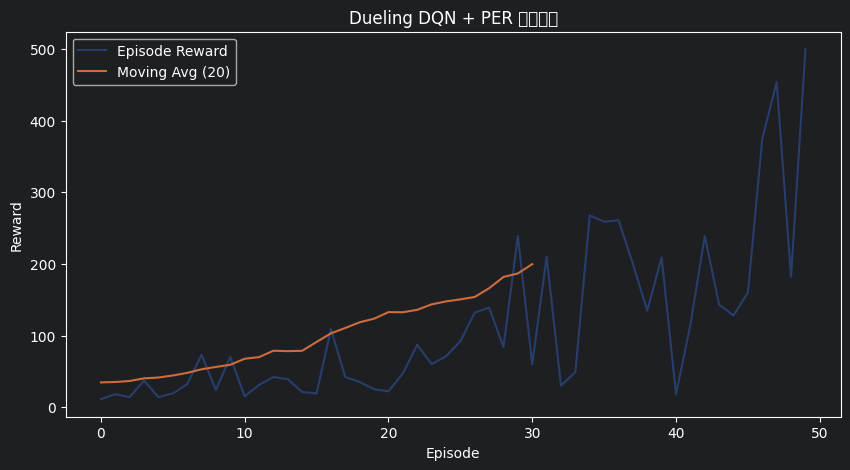

模型保存在: models/dueling_dqn_cartpole.pth
模型已从 models/dueling_dqn_cartpole.pth 加载

开始测试并录制 GIF...
测试回合 1: 奖励 = 500.0
测试回合 2: 奖励 = 500.0
测试回合 3: 奖励 = 500.0
测试回合 4: 奖励 = 500.0
测试回合 5: 奖励 = 500.0
测试回合 6: 奖励 = 500.0
测试回合 7: 奖励 = 500.0
测试回合 8: 奖励 = 500.0
测试回合 9: 奖励 = 500.0
测试回合 10: 奖励 = 500.0


In [ ]:
# 运行主函数开始训练

main()                                                                                   # 训练 Dueling DQN + PER 智能体，训练完自动绘制奖励曲线

# 训练结束后加载最优模型测试，并生成 GIF 动图 cartpole_agent.gif
test_agent()                                                                             # 默认测试 10 回合，逐帧录制并保存为 cartpole_agent.gif
